# Mini projet : impact du bruit sur les performances d'un classifieur d'images

**Jeu de données :** Fashion-MNIST, **5 classes**, **100 images par classe** (500 images au total), organisé en un dossier par classe.

**Plan**
1. Préparation et exploration
2. Apprentissage avec les images propres (descripteur HOG, classifieurs SVM et k-NN)
3. Apprentissage avec les images bruitées (bruit gaussien, sel & poivre, speckle ; 10 %, 25 %, 50 %)
4. Comparaison de toutes les expérimentations

In [1]:
import os, gzip, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

from skimage.feature import hog
from skimage.util import random_noise

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay, f1_score)

SEED = 42
rng = np.random.default_rng(SEED)
IMG_SIZE = 64
plt.rcParams['figure.dpi'] = 90

## 0. Création du jeu de données (un dossier par classe)

On télécharge Fashion-MNIST (partie *t10k*) puis on enregistre **100 images par classe** pour 5 classes,
au format PNG, dans `data/fashion_mnist/<classe>/`. Cette étape n'est faite qu'une seule fois.

In [2]:
DATA_DIR = 'data/fashion_mnist'
CLASSES = {0: 'tshirt', 1: 'pantalon', 2: 'pull', 7: 'basket', 8: 'sac'}   # 5 classes retenues
N_PER_CLASS = 100

def _download(name):
    url = f'https://github.com/zalandoresearch/fashion-mnist/raw/master/data/fashion/{name}'
    path = os.path.join('data', name)
    if not os.path.exists(path):
        os.makedirs('data', exist_ok=True)
        urllib.request.urlretrieve(url, path)
    return path

if not os.path.isdir(DATA_DIR):
    with gzip.open(_download('t10k-images-idx3-ubyte.gz')) as f:
        X_raw = np.frombuffer(f.read(), np.uint8, offset=16).reshape(-1, 28, 28)
    with gzip.open(_download('t10k-labels-idx1-ubyte.gz')) as f:
        y_raw = np.frombuffer(f.read(), np.uint8, offset=8)
    for lab, name in CLASSES.items():
        os.makedirs(os.path.join(DATA_DIR, name), exist_ok=True)
        idx = np.where(y_raw == lab)[0][:N_PER_CLASS]
        for k, i in enumerate(idx):
            Image.fromarray(X_raw[i]).save(os.path.join(DATA_DIR, name, f'{name}_{k:03d}.png'))
print(sorted(os.listdir(DATA_DIR)))

['basket', 'pantalon', 'pull', 'sac', 'tshirt']


# Partie 1 : Préparation et exploration

### 1.1 Chargement des images

In [3]:
class_names = sorted(os.listdir(DATA_DIR))
images, labels, paths = [], [], []
for c, name in enumerate(class_names):
    folder = os.path.join(DATA_DIR, name)
    for fname in sorted(os.listdir(folder))[:N_PER_CLASS]:      # max 100 images / classe
        img = Image.open(os.path.join(folder, fname))
        images.append(img); labels.append(c); paths.append(fname)
labels = np.array(labels)
print(f'{len(images)} images chargées, {len(class_names)} classes : {class_names}')
print('Taille originale :', images[0].size, '- mode :', images[0].mode)

500 images chargées, 5 classes : ['basket', 'pantalon', 'pull', 'sac', 'tshirt']
Taille originale : (28, 28) - mode : L


### 1.2 Quelques exemples de chaque classe

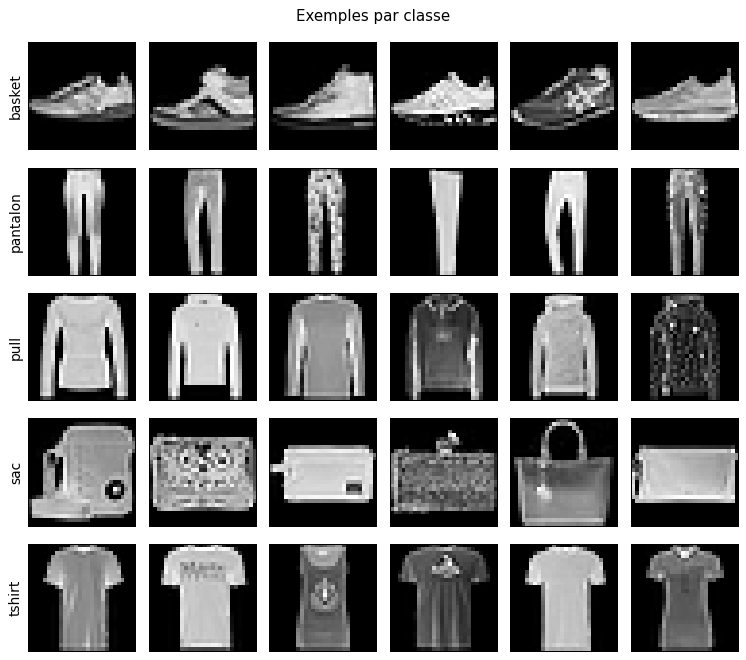

In [4]:
n_ex = 6
fig, axes = plt.subplots(len(class_names), n_ex, figsize=(n_ex * 1.4, len(class_names) * 1.5))
for c, name in enumerate(class_names):
    idx = rng.choice(np.where(labels == c)[0], n_ex, replace=False)
    for j, i in enumerate(idx):
        ax = axes[c, j]
        ax.imshow(images[i], cmap='gray'); ax.set_xticks([]); ax.set_yticks([])
        if j == 0: ax.set_ylabel(name, fontsize=11)
plt.suptitle('Exemples par classe'); plt.tight_layout(); plt.show()

### 1.3 Répartition des classes

,nb images
basket,100
pantalon,100
pull,100
sac,100
tshirt,100


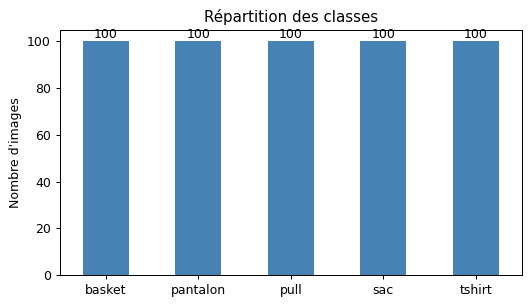

In [5]:
counts = pd.Series(labels).map(dict(enumerate(class_names))).value_counts().reindex(class_names)
display(counts.to_frame('nb images'))
ax = counts.plot.bar(color='steelblue', figsize=(6, 3.5), rot=0)
ax.bar_label(ax.containers[0]); ax.set_ylabel("Nombre d'images"); ax.set_title('Répartition des classes')
plt.tight_layout(); plt.show()

Le jeu de données est **parfaitement équilibré** (100 images par classe) : l'accuracy est donc une métrique pertinente,
et il n'y a pas besoin de rééquilibrage.

### 1.4 Redimensionnement 64×64 et niveaux de gris

**Choix : niveaux de gris.** Les images Fashion-MNIST sont nativement en niveaux de gris (1 canal) : garder 3 canaux
n'apporterait aucune information et multiplierait la taille des vecteurs. De plus, les descripteurs utilisés (HOG)
travaillent sur l'intensité / les gradients. On normalise les pixels dans [0, 1].

X : (500, 64, 64) float32 [0.0, 1.0]


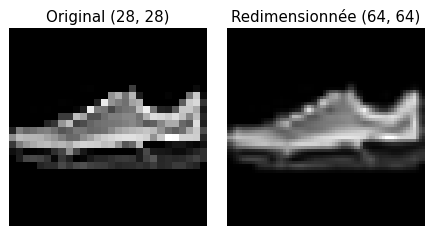

In [6]:
X = np.stack([np.asarray(img.convert('L').resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR), dtype=np.float32) / 255.
              for img in images])
y = labels
print('X :', X.shape, X.dtype, f'[{X.min():.1f}, {X.max():.1f}]')

fig, axes = plt.subplots(1, 2, figsize=(5, 2.6))
axes[0].imshow(images[0], cmap='gray'); axes[0].set_title(f'Original {images[0].size}')
axes[1].imshow(X[0], cmap='gray');      axes[1].set_title(f'Redimensionnée {X[0].shape}')
for a in axes: a.axis('off')
plt.tight_layout(); plt.show()

### 1.5 Séparation 70 % apprentissage / 30 % test (stratifiée)

In [7]:
idx_all = np.arange(len(X))
idx_train, idx_test = train_test_split(idx_all, test_size=0.30, stratify=y, random_state=SEED)
X_train, X_test, y_train, y_test = X[idx_train], X[idx_test], y[idx_train], y[idx_test]
print('Train :', X_train.shape, '| Test :', X_test.shape)
display(pd.DataFrame({'train': np.bincount(y_train), 'test': np.bincount(y_test)}, index=class_names))

Train : (350, 64, 64) | Test : (150, 64, 64)


,train,test
basket,70,30
pantalon,70,30
pull,70,30
sac,70,30
tshirt,70,30


# Partie 2 : Apprentissage avec les images propres

### 2.1 Extraction de caractéristiques : HOG

On choisit **HOG** (Histogram of Oriented Gradients) : il décrit la forme des objets via la distribution des orientations
des gradients locaux, ce qui convient bien aux vêtements (silhouettes très différentes d'une classe à l'autre).
Paramètres : 9 orientations, cellules 8×8, blocs 2×2 → vecteur de 1764 dimensions.

Descripteurs HOG : (350, 1764) (150, 1764)


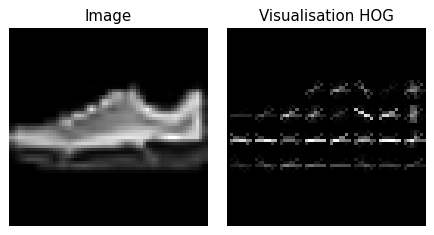

In [8]:
HOG_PARAMS = dict(orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2), block_norm='L2-Hys')

def extract_hog(imgs):
    return np.array([hog(im, **HOG_PARAMS) for im in imgs])

F_train, F_test = extract_hog(X_train), extract_hog(X_test)
print('Descripteurs HOG :', F_train.shape, F_test.shape)

_, hog_img = hog(X[0], visualize=True, **HOG_PARAMS)
fig, axes = plt.subplots(1, 2, figsize=(5, 2.6))
axes[0].imshow(X[0], cmap='gray'); axes[0].set_title('Image')
axes[1].imshow(hog_img, cmap='gray'); axes[1].set_title('Visualisation HOG')
for a in axes: a.axis('off')
plt.tight_layout(); plt.show()

### 2.2 Entraînement de deux classifieurs : SVM (noyau RBF) et k-NN (k = 5)

Les descripteurs sont standardisés (`StandardScaler`) avant classification, dans un pipeline pour éviter toute fuite d'information du test.

In [9]:
def make_classifiers():
    return {
        'SVM':  make_pipeline(StandardScaler(), SVC(kernel='rbf', C=10, gamma='scale', random_state=SEED)),
        'k-NN': make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    }

def evaluate(clf_name, y_true, y_pred, title, ax=None, verbose=True):
    acc = accuracy_score(y_true, y_pred)
    if verbose:
        print(f'=== {title} - {clf_name} : accuracy = {acc:.3f} ===')
        print(classification_report(y_true, y_pred, target_names=class_names, digits=3))
    if ax is not None:
        ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred), display_labels=class_names).plot(
            ax=ax, cmap='Blues', colorbar=False, xticks_rotation=45)
        ax.set_title(f'{clf_name} - acc {acc:.3f}', fontsize=10)
    return acc, f1_score(y_true, y_pred, average='macro')

results = []   # tableau récapitulatif de toutes les expériences

### 2.3 Évaluation sur le test : accuracy, matrice de confusion, précision / rappel / F1 par classe

=== Images propres - SVM : accuracy = 0.960 ===
              precision    recall  f1-score   support

      basket      1.000     1.000     1.000        30
    pantalon      1.000     0.967     0.983        30
        pull      0.853     0.967     0.906        30
         sac      1.000     1.000     1.000        30
      tshirt      0.963     0.867     0.912        30

    accuracy                          0.960       150
   macro avg      0.963     0.960     0.960       150
weighted avg      0.963     0.960     0.960       150



=== Images propres - k-NN : accuracy = 0.920 ===
              precision    recall  f1-score   support

      basket      0.968     1.000     0.984        30
    pantalon      0.906     0.967     0.935        30
        pull      0.824     0.933     0.875        30
         sac      1.000     0.900     0.947        30
      tshirt      0.923     0.800     0.857        30

    accuracy                          0.920       150
   macro avg      0.924     0.920     0.920       150
weighted avg      0.924     0.920     0.920       150



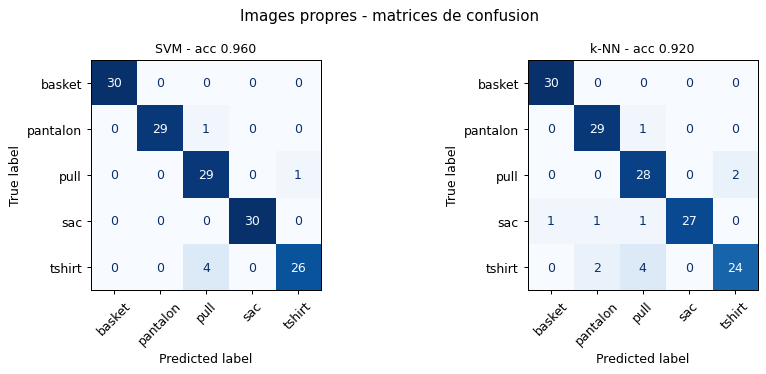

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, (name, clf) in zip(axes, make_classifiers().items()):
    clf.fit(F_train, y_train)
    acc, f1 = evaluate(name, y_test, clf.predict(F_test), 'Images propres', ax=ax)
    results.append(dict(bruit='aucun', taux=0, classifieur=name, accuracy=acc, f1_macro=f1))
plt.suptitle('Images propres - matrices de confusion'); plt.tight_layout(); plt.show()

# Partie 3 : Apprentissage avec les images bruitées

### 3.1 Types de bruit

Trois bruits classiques sont étudiés :
- **Gaussien** (additif, σ = 0,2) : modélise le bruit électronique du capteur ;
- **Sel & poivre** (impulsionnel, 10 % des pixels) : pixels morts / erreurs de transmission ;
- **Speckle** (multiplicatif, variance 0,5) : bruit proportionnel à l'intensité (imagerie radar, échographie).

In [11]:
NOISES = {
    'gaussien':     lambda im, r: random_noise(im, mode='gaussian', var=0.2 ** 2, rng=r),
    'sel & poivre': lambda im, r: random_noise(im, mode='s&p', amount=0.10, rng=r),
    'speckle':      lambda im, r: random_noise(im, mode='speckle', var=0.5, rng=r),
}
RATES = [0.10, 0.25, 0.50]

### 3.2 Visualisation d'une même image avant et après chaque bruit

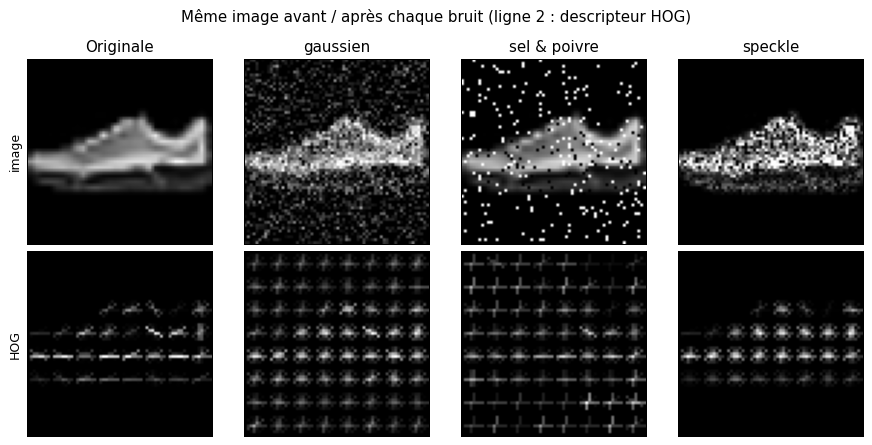

In [12]:
i0 = np.where(y == class_names.index('basket'))[0][0]
fig, axes = plt.subplots(2, 1 + len(NOISES), figsize=(10, 5))
axes[0, 0].imshow(X[i0], cmap='gray', vmin=0, vmax=1); axes[0, 0].set_title('Originale')
_, h = hog(X[i0], visualize=True, **HOG_PARAMS); axes[1, 0].imshow(h, cmap='gray')
for j, (nname, fn) in enumerate(NOISES.items(), start=1):
    noisy = fn(X[i0], SEED)
    axes[0, j].imshow(noisy, cmap='gray', vmin=0, vmax=1); axes[0, j].set_title(nname)
    _, h = hog(noisy, visualize=True, **HOG_PARAMS); axes[1, j].imshow(h, cmap='gray')
axes[0, 0].set_ylabel('image'); axes[1, 0].set_ylabel('HOG')
for a in axes.ravel(): a.set_xticks([]); a.set_yticks([])
plt.suptitle('Même image avant / après chaque bruit (ligne 2 : descripteur HOG)'); plt.tight_layout(); plt.show()

On voit que le bruit gaussien et le sel & poivre créent beaucoup de gradients parasites dans le fond, ce qui perturbe le HOG ;
le speckle, multiplicatif, n'affecte que les zones non noires (l'objet) et laisse le fond intact.

### 3.3 Protocole

Pour chaque type de bruit et chaque taux (10 %, 25 %, 50 % **de la taille de l'ensemble**, soit 50, 125, 250 images) :
1. on tire **aléatoirement** les images à bruiter parmi les 500 ;
2. on sépare en 70 / 30 en **stratifiant sur le couple (classe, bruitée ou non)** : chaque sous-ensemble contient donc
   des images bruitées, dans la même proportion, et pour chaque classe ;
3. on extrait les **mêmes descripteurs HOG** ;
4. on entraîne les **mêmes classifieurs** (SVM, k-NN) et on évalue sur le test.

In [13]:
def make_noisy_dataset(noise_name, rate, seed=SEED):
    r = np.random.default_rng(seed)
    n_noisy = int(round(rate * len(X)))
    noisy_idx = r.choice(len(X), n_noisy, replace=False)          # choix aléatoire
    Xn = X.copy()
    is_noisy = np.zeros(len(X), dtype=bool); is_noisy[noisy_idx] = True
    for i in noisy_idx:
        Xn[i] = NOISES[noise_name](X[i], r)
    return Xn.astype(np.float32), is_noisy

def run_experiment(noise_name, rate, show=True):
    Xn, is_noisy = make_noisy_dataset(noise_name, rate)
    strata = y * 2 + is_noisy                                      # strate = (classe, bruitée)
    tr, te = train_test_split(np.arange(len(Xn)), test_size=0.30, stratify=strata, random_state=SEED)
    print(f'\n########## Bruit {noise_name} - {int(rate*100)} % : '
          f'{is_noisy[tr].sum()} images bruitées en train, {is_noisy[te].sum()} en test ##########')
    Ftr, Fte = extract_hog(Xn[tr]), extract_hog(Xn[te])
    fig, axes = plt.subplots(1, 2, figsize=(10, 4.2)) if show else (None, [None, None])
    for ax, (name, clf) in zip(axes, make_classifiers().items()):
        clf.fit(Ftr, y[tr])
        pred = clf.predict(Fte)
        acc, f1 = evaluate(name, y[te], pred, f'{noise_name} {int(rate*100)} %', ax=ax, verbose=show)
        noisy_te = is_noisy[te]
        results.append(dict(bruit=noise_name, taux=int(rate * 100), classifieur=name, accuracy=acc, f1_macro=f1,
                            acc_test_propres=accuracy_score(y[te][~noisy_te], pred[~noisy_te]),
                            acc_test_bruitees=accuracy_score(y[te][noisy_te], pred[noisy_te])))
    if show:
        fig.suptitle(f'Bruit {noise_name} - {int(rate*100)} % des images'); plt.tight_layout(); plt.show()

### 3.4 Expériences : bruit gaussien


########## Bruit gaussien - 10 % : 34 images bruitées en train, 16 en test ##########


=== gaussien 10 % - SVM : accuracy = 0.987 ===
              precision    recall  f1-score   support

      basket      1.000     1.000     1.000        30
    pantalon      1.000     1.000     1.000        30
        pull      1.000     0.967     0.983        30
         sac      1.000     0.967     0.983        30
      tshirt      0.938     1.000     0.968        30

    accuracy                          0.987       150
   macro avg      0.988     0.987     0.987       150
weighted avg      0.988     0.987     0.987       150

=== gaussien 10 % - k-NN : accuracy = 0.907 ===
              precision    recall  f1-score   support

      basket      0.938     1.000     0.968        30
    pantalon      0.882     1.000     0.938        30
        pull      0.806     0.967     0.879        30
         sac      1.000     0.767     0.868        30
      tshirt      0.960     0.800     0.873        30

    accuracy                          0.907       150
   macro avg      0.917     0.907   

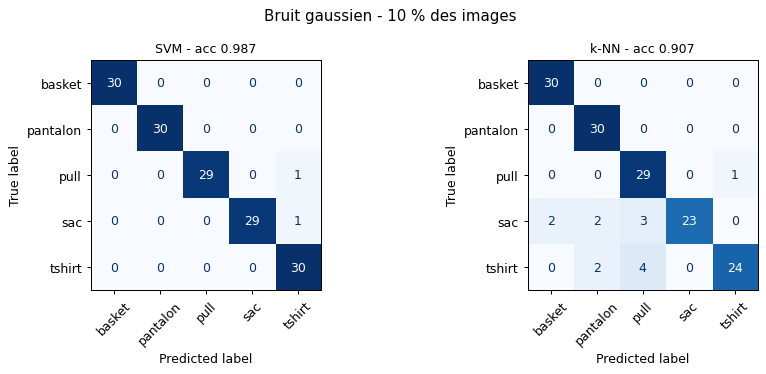


########## Bruit gaussien - 25 % : 89 images bruitées en train, 36 en test ##########


=== gaussien 25 % - SVM : accuracy = 0.967 ===
              precision    recall  f1-score   support

      basket      1.000     1.000     1.000        30
    pantalon      0.968     1.000     0.984        30
        pull      0.966     0.933     0.949        30
         sac      0.968     1.000     0.984        30
      tshirt      0.931     0.900     0.915        30

    accuracy                          0.967       150
   macro avg      0.966     0.967     0.966       150
weighted avg      0.966     0.967     0.966       150



=== gaussien 25 % - k-NN : accuracy = 0.907 ===
              precision    recall  f1-score   support

      basket      0.935     0.967     0.951        30
    pantalon      0.938     1.000     0.968        30
        pull      0.800     0.933     0.862        30
         sac      0.958     0.767     0.852        30
      tshirt      0.929     0.867     0.897        30

    accuracy                          0.907       150
   macro avg      0.912     0.907     0.906       150
weighted avg      0.912     0.907     0.906       150



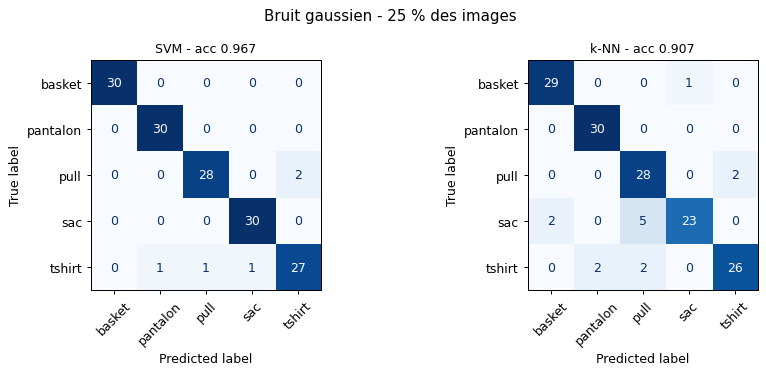


########## Bruit gaussien - 50 % : 175 images bruitées en train, 75 en test ##########


=== gaussien 50 % - SVM : accuracy = 0.927 ===
              precision    recall  f1-score   support

      basket      1.000     1.000     1.000        30
    pantalon      1.000     0.867     0.929        30
        pull      0.871     0.900     0.885        30
         sac      0.935     0.967     0.951        30
      tshirt      0.844     0.900     0.871        30

    accuracy                          0.927       150
   macro avg      0.930     0.927     0.927       150
weighted avg      0.930     0.927     0.927       150

=== gaussien 50 % - k-NN : accuracy = 0.840 ===
              precision    recall  f1-score   support

      basket      0.968     1.000     0.984        30
    pantalon      0.818     0.900     0.857        30
        pull      0.651     0.933     0.767        30
         sac      1.000     0.667     0.800        30
      tshirt      0.913     0.700     0.792        30

    accuracy                          0.840       150
   macro avg      0.870     0.840   

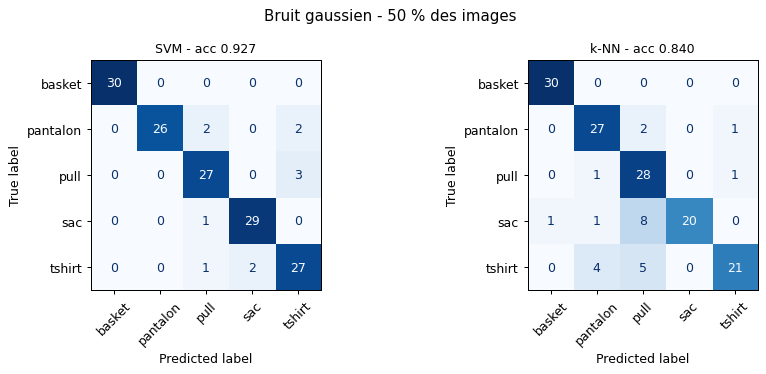

In [14]:
for rate in RATES: run_experiment('gaussien', rate)

### 3.5 Expériences : bruit sel & poivre


########## Bruit sel & poivre - 10 % : 34 images bruitées en train, 16 en test ##########


=== sel & poivre 10 % - SVM : accuracy = 0.987 ===
              precision    recall  f1-score   support

      basket      1.000     1.000     1.000        30
    pantalon      1.000     1.000     1.000        30
        pull      1.000     0.967     0.983        30
         sac      1.000     0.967     0.983        30
      tshirt      0.938     1.000     0.968        30

    accuracy                          0.987       150
   macro avg      0.988     0.987     0.987       150
weighted avg      0.988     0.987     0.987       150

=== sel & poivre 10 % - k-NN : accuracy = 0.880 ===
              precision    recall  f1-score   support

      basket      0.938     1.000     0.968        30
    pantalon      0.882     1.000     0.938        30
        pull      0.725     0.967     0.829        30
         sac      1.000     0.600     0.750        30
      tshirt      0.962     0.833     0.893        30

    accuracy                          0.880       150
   macro avg      0.901     

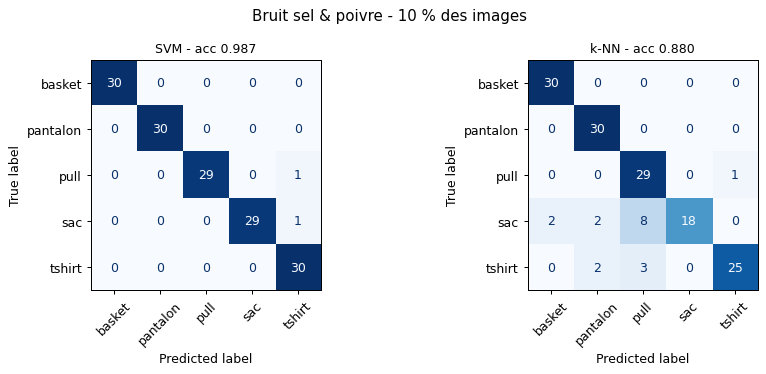


########## Bruit sel & poivre - 25 % : 89 images bruitées en train, 36 en test ##########


=== sel & poivre 25 % - SVM : accuracy = 0.967 ===
              precision    recall  f1-score   support

      basket      1.000     1.000     1.000        30
    pantalon      0.938     1.000     0.968        30
        pull      0.966     0.933     0.949        30
         sac      0.968     1.000     0.984        30
      tshirt      0.964     0.900     0.931        30

    accuracy                          0.967       150
   macro avg      0.967     0.967     0.966       150
weighted avg      0.967     0.967     0.966       150

=== sel & poivre 25 % - k-NN : accuracy = 0.920 ===
              precision    recall  f1-score   support

      basket      0.909     1.000     0.952        30
    pantalon      0.909     1.000     0.952        30
        pull      0.829     0.967     0.892        30
         sac      1.000     0.767     0.868        30
      tshirt      1.000     0.867     0.929        30

    accuracy                          0.920       150
   macro avg      0.929     

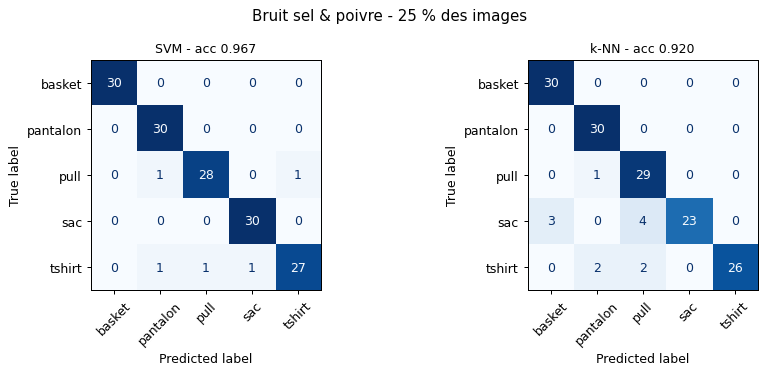


########## Bruit sel & poivre - 50 % : 175 images bruitées en train, 75 en test ##########


=== sel & poivre 50 % - SVM : accuracy = 0.920 ===
              precision    recall  f1-score   support

      basket      1.000     0.967     0.983        30
    pantalon      1.000     0.933     0.966        30
        pull      0.844     0.900     0.871        30
         sac      0.853     0.967     0.906        30
      tshirt      0.926     0.833     0.877        30

    accuracy                          0.920       150
   macro avg      0.925     0.920     0.921       150
weighted avg      0.925     0.920     0.921       150

=== sel & poivre 50 % - k-NN : accuracy = 0.867 ===
              precision    recall  f1-score   support

      basket      0.968     1.000     0.984        30
    pantalon      0.848     0.933     0.889        30
        pull      0.667     0.933     0.778        30
         sac      1.000     0.733     0.846        30
      tshirt      1.000     0.733     0.846        30

    accuracy                          0.867       150
   macro avg      0.897     

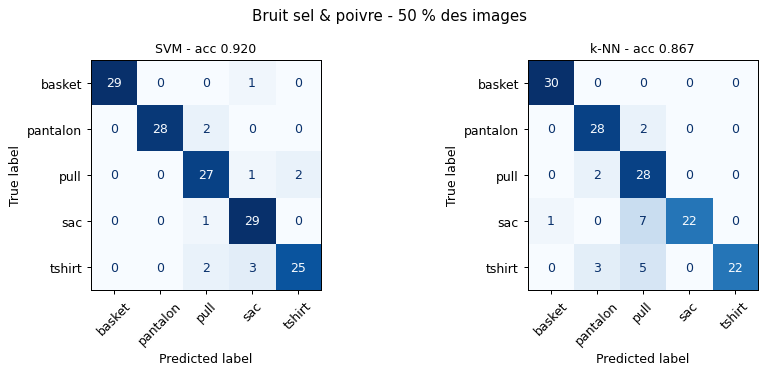

In [15]:
for rate in RATES: run_experiment('sel & poivre', rate)

### 3.6 Expériences : bruit speckle


########## Bruit speckle - 10 % : 34 images bruitées en train, 16 en test ##########


=== speckle 10 % - SVM : accuracy = 0.980 ===
              precision    recall  f1-score   support

      basket      1.000     1.000     1.000        30
    pantalon      1.000     1.000     1.000        30
        pull      1.000     0.933     0.966        30
         sac      0.967     0.967     0.967        30
      tshirt      0.938     1.000     0.968        30

    accuracy                          0.980       150
   macro avg      0.981     0.980     0.980       150
weighted avg      0.981     0.980     0.980       150

=== speckle 10 % - k-NN : accuracy = 0.907 ===
              precision    recall  f1-score   support

      basket      0.938     1.000     0.968        30
    pantalon      0.882     1.000     0.938        30
        pull      0.806     0.967     0.879        30
         sac      1.000     0.733     0.846        30
      tshirt      0.962     0.833     0.893        30

    accuracy                          0.907       150
   macro avg      0.917     0.907     

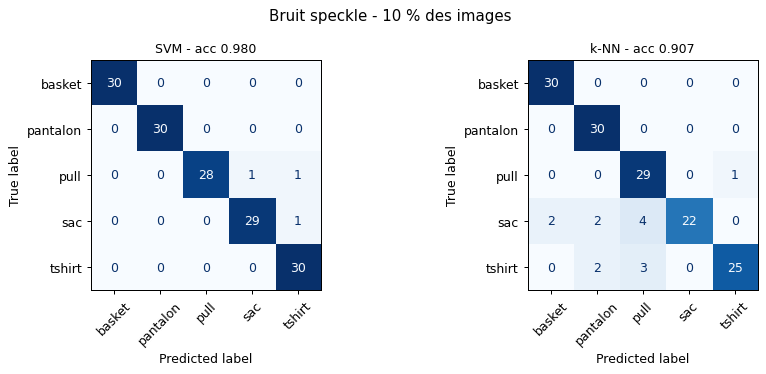


########## Bruit speckle - 25 % : 89 images bruitées en train, 36 en test ##########


=== speckle 25 % - SVM : accuracy = 0.973 ===
              precision    recall  f1-score   support

      basket      1.000     1.000     1.000        30
    pantalon      0.968     1.000     0.984        30
        pull      0.967     0.967     0.967        30
         sac      0.968     1.000     0.984        30
      tshirt      0.964     0.900     0.931        30

    accuracy                          0.973       150
   macro avg      0.973     0.973     0.973       150
weighted avg      0.973     0.973     0.973       150

=== speckle 25 % - k-NN : accuracy = 0.893 ===
              precision    recall  f1-score   support

      basket      0.938     1.000     0.968        30
    pantalon      0.938     1.000     0.968        30
        pull      0.725     0.967     0.829        30
         sac      1.000     0.633     0.776        30
      tshirt      0.963     0.867     0.912        30

    accuracy                          0.893       150
   macro avg      0.913     0.893     

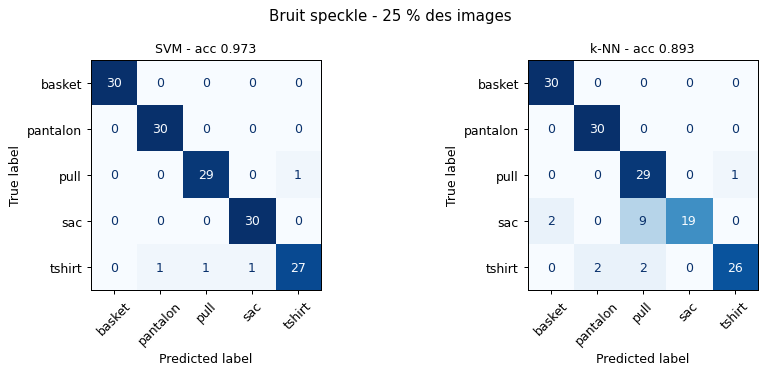


########## Bruit speckle - 50 % : 175 images bruitées en train, 75 en test ##########


=== speckle 50 % - SVM : accuracy = 0.907 ===
              precision    recall  f1-score   support

      basket      1.000     0.967     0.983        30
    pantalon      0.963     0.867     0.912        30
        pull      0.871     0.900     0.885        30
         sac      0.879     0.967     0.921        30
      tshirt      0.833     0.833     0.833        30

    accuracy                          0.907       150
   macro avg      0.909     0.907     0.907       150
weighted avg      0.909     0.907     0.907       150

=== speckle 50 % - k-NN : accuracy = 0.880 ===
              precision    recall  f1-score   support

      basket      1.000     1.000     1.000        30
    pantalon      0.879     0.967     0.921        30
        pull      0.718     0.933     0.812        30
         sac      0.923     0.800     0.857        30
      tshirt      0.955     0.700     0.808        30

    accuracy                          0.880       150
   macro avg      0.895     0.880     

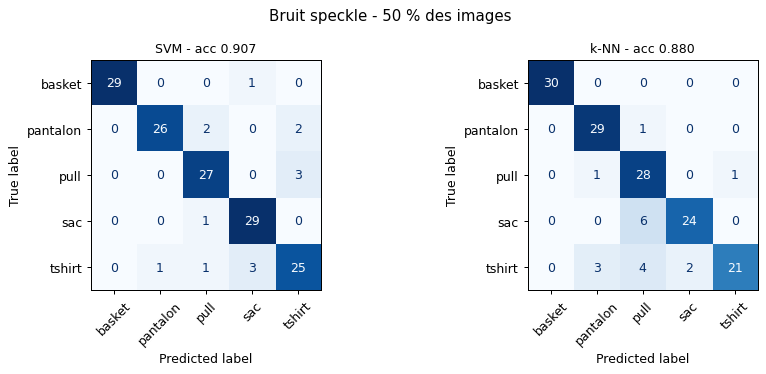

In [16]:
for rate in RATES: run_experiment('speckle', rate)

# 4. Comparaison de toutes les expérimentations
### 4.1 Tableau récapitulatif

In [17]:
res = pd.DataFrame(results)
display(res.round(3))

pivot = res.pivot_table(index=['bruit', 'taux'], columns='classifieur', values=['accuracy', 'f1_macro']).round(3)
display(pivot)

,bruit,taux,classifieur,accuracy,f1_macro,acc_test_propres,acc_test_bruitees
0,aucun,0,SVM,0.960,0.960,NaN,NaN
1,aucun,0,k-NN,0.920,0.920,NaN,NaN
2,gaussien,10,SVM,0.987,0.987,0.985,1.000
3,gaussien,10,k-NN,0.907,0.905,0.903,0.938
4,gaussien,25,SVM,0.967,0.966,0.974,0.944
5,gaussien,25,k-NN,0.907,0.906,0.921,0.861
6,gaussien,50,SVM,0.927,0.927,0.960,0.893
7,gaussien,50,k-NN,0.840,0.840,0.867,0.813
8,sel & poivre,10,SVM,0.987,0.987,0.985,1.000
9,sel & poivre,10,k-NN,0.880,0.875,0.896,0.750


accuracy        f1_macro       
classifieur            SVM   k-NN      SVM   k-NN
bruit        taux                                
aucun        0       0.960  0.920    0.960  0.920
gaussien     10      0.987  0.907    0.987  0.905
             25      0.967  0.907    0.966  0.906
             50      0.927  0.840    0.927  0.840
sel & poivre 10      0.987  0.880    0.987  0.875
             25      0.967  0.920    0.966  0.919
             50      0.920  0.867    0.921  0.869
speckle      10      0.980  0.907    0.980  0.905
             25      0.973  0.893    0.973  0.890
             50      0.907  0.880    0.907  0.879

### 4.2 Accuracy en fonction du taux d'images bruitées

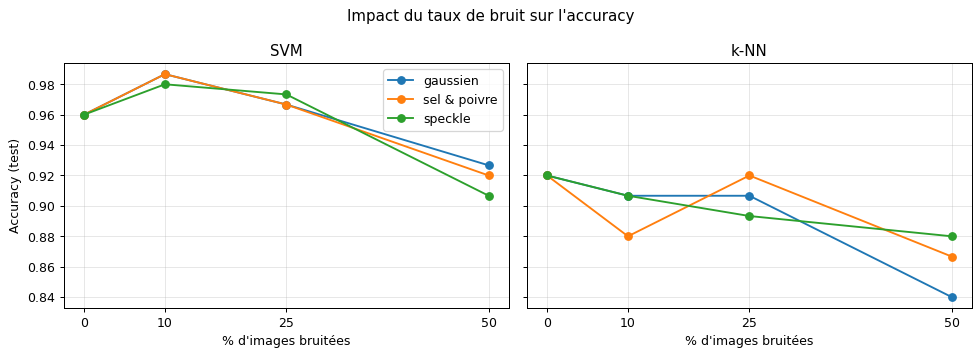

In [18]:
clean = res[res.bruit == 'aucun'].set_index('classifieur')
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, clf_name in zip(axes, ['SVM', 'k-NN']):
    for nname in NOISES:
        sub = res[(res.bruit == nname) & (res.classifieur == clf_name)]
        xs = [0] + sub.taux.tolist()
        ys = [clean.loc[clf_name, 'accuracy']] + sub.accuracy.tolist()
        ax.plot(xs, ys, marker='o', label=nname)
    ax.set_title(clf_name); ax.set_xlabel("% d'images bruitées"); ax.set_xticks([0, 10, 25, 50]); ax.grid(alpha=.3)
axes[0].set_ylabel('Accuracy (test)'); axes[0].legend()
plt.suptitle("Impact du taux de bruit sur l'accuracy"); plt.tight_layout(); plt.show()

### 4.3 Accuracy sur les images de test propres vs bruitées

C:\Users\marie\AppData\Local\Temp\ipykernel_37668\3910728174.py:2: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  noisy_res['config'] = noisy_res.bruit + ' ' + noisy_res.taux.astype(str) + '%'


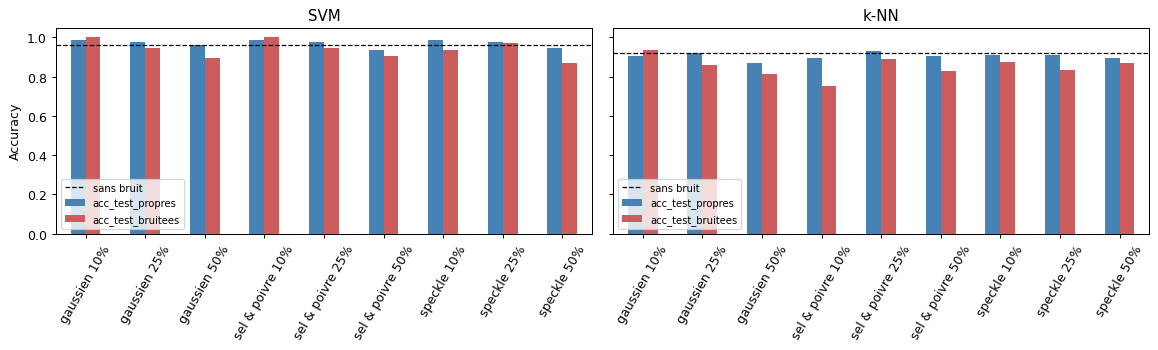

In [19]:
noisy_res = res[res.bruit != 'aucun'].copy()
noisy_res['config'] = noisy_res.bruit + ' ' + noisy_res.taux.astype(str) + '%'
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, clf_name in zip(axes, ['SVM', 'k-NN']):
    sub = noisy_res[noisy_res.classifieur == clf_name].set_index('config')
    sub[['acc_test_propres', 'acc_test_bruitees']].plot.bar(ax=ax, rot=60, color=['steelblue', 'indianred'])
    ax.axhline(clean.loc[clf_name, 'accuracy'], ls='--', c='k', lw=1, label='sans bruit')
    ax.set_title(clf_name); ax.set_xlabel(''); ax.legend(fontsize=8)
axes[0].set_ylabel('Accuracy')
plt.tight_layout(); plt.show()

In [20]:
# Synthèse automatique : perte d'accuracy par rapport aux images propres
res['perte_vs_propre'] = res.apply(lambda r: clean.loc[r.classifieur, 'accuracy'] - r.accuracy, axis=1)
display(res[res.bruit != 'aucun'].pivot_table(index='bruit', columns=['classifieur', 'taux'],
                                               values='perte_vs_propre').round(3))

C:\Users\marie\AppData\Local\Temp\ipykernel_37668\2462000427.py:2: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  res['perte_vs_propre'] = res.apply(lambda r: clean.loc[r.classifieur, 'accuracy'] - r.accuracy, axis=1)


classifieur     SVM                 k-NN              
taux             10     25     50     10     25     50
bruit                                                 
gaussien     -0.027 -0.007  0.033  0.013  0.013  0.080
sel & poivre -0.027 -0.007  0.040  0.040  0.000  0.053
speckle      -0.020 -0.013  0.053  0.013  0.027  0.040

### 4.4 Robustesse des conclusions : moyenne sur 10 tirages

Avec seulement 150 images de test, **une image = 0,67 point d'accuracy** : un seul tirage (choix des images bruitées +
découpage train/test) peut donner un résultat trompeur (par ex. une accuracy *plus haute* avec 10 % de bruit que sans bruit,
simplement parce que le découpage est différent). On répète donc chaque expérience avec **10 graines aléatoires**
et on rapporte la moyenne ± écart-type.

In [21]:
N_REP = 10

def quick_run(noise_name, rate, seed):
    if noise_name == 'aucun':
        Xn, is_noisy = X, np.zeros(len(X), bool)
    else:
        Xn, is_noisy = make_noisy_dataset(noise_name, rate, seed=seed)
    tr, te = train_test_split(np.arange(len(Xn)), test_size=0.30, stratify=y * 2 + is_noisy, random_state=seed)
    Ftr, Fte = extract_hog(Xn[tr]), extract_hog(Xn[te])
    out = {}
    for name, clf in make_classifiers().items():
        out[name] = accuracy_score(y[te], clf.fit(Ftr, y[tr]).predict(Fte))
    return out

rep = []
for noise_name, rate in [('aucun', 0)] + [(n, r) for n in NOISES for r in RATES]:
    for s in range(N_REP):
        for clf_name, acc in quick_run(noise_name, rate, seed=100 + s).items():
            rep.append(dict(bruit=noise_name, taux=int(rate * 100), classifieur=clf_name, accuracy=acc))
rep = pd.DataFrame(rep)
summary = rep.groupby(['bruit', 'taux', 'classifieur']).accuracy.agg(['mean', 'std']).unstack('classifieur').round(3)
display(summary)

mean           std       
classifieur          SVM   k-NN    SVM   k-NN
bruit        taux                            
aucun        0     0.955  0.923  0.017  0.023
gaussien     10    0.953  0.904  0.014  0.016
             25    0.953  0.903  0.013  0.027
             50    0.945  0.893  0.018  0.017
sel & poivre 10    0.954  0.899  0.013  0.022
             25    0.965  0.894  0.013  0.029
             50    0.946  0.890  0.013  0.020
speckle      10    0.959  0.909  0.014  0.017
             25    0.968  0.909  0.009  0.023
             50    0.949  0.909  0.014  0.013

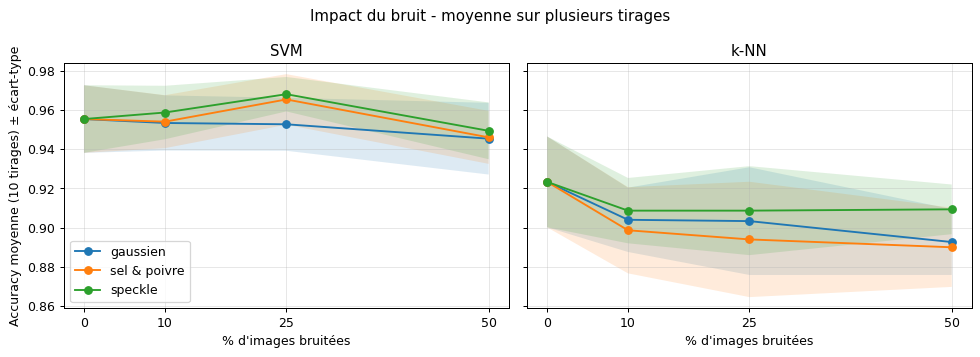

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
base = rep[rep.bruit == 'aucun'].groupby('classifieur').accuracy.agg(['mean', 'std'])
for ax, clf_name in zip(axes, ['SVM', 'k-NN']):
    for nname in NOISES:
        g = rep[(rep.bruit == nname) & (rep.classifieur == clf_name)].groupby('taux').accuracy.agg(['mean', 'std'])
        xs = [0] + g.index.tolist()
        m = np.r_[base.loc[clf_name, 'mean'], g['mean']]; s = np.r_[base.loc[clf_name, 'std'], g['std']]
        ax.plot(xs, m, marker='o', label=nname); ax.fill_between(xs, m - s, m + s, alpha=.15)
    ax.set_title(clf_name); ax.set_xlabel("% d'images bruitées"); ax.set_xticks([0, 10, 25, 50]); ax.grid(alpha=.3)
axes[0].set_ylabel(f'Accuracy moyenne ({N_REP} tirages) ± écart-type'); axes[0].legend()
plt.suptitle('Impact du bruit - moyenne sur plusieurs tirages'); plt.tight_layout(); plt.show()

### 4.5 Conclusion

- **Référence (images propres)** : HOG + SVM atteint ≈ 95,5 % d'accuracy (moyenne sur 10 tirages), contre ≈ 92 % pour HOG + k-NN.
  Les confusions se concentrent sur les deux classes de hauts (**t-shirt / pull**), aux silhouettes proches ;
  pantalon, sac et basket sont reconnus presque parfaitement.
- **Effet du taux de bruit** : la dégradation augmente avec la proportion d'images bruitées, et elle est surtout visible à **50 %**.
  Sur un seul tirage, le SVM passe de 0,96 à ≈ 0,91-0,93 à 50 % de bruit, et le k-NN de 0,92 à ≈ 0,84-0,88.
- **Prudence sur un seul tirage** : à 10 %, une expérience isolée donne parfois une accuracy *supérieure* au cas propre (0,987).
  C'est un effet du découpage train/test, pas du bruit. La moyenne sur 10 tirages montre que, pour le SVM, les écarts restent
  du même ordre que l'écart-type (≈ 1,5 point) : **le SVM est très robuste** à ces niveaux de bruit.
- **Classifieurs** : le **k-NN est plus sensible** au bruit (≈ −2 à −3 points en moyenne dès 10 %). La distance euclidienne
  dans l'espace HOG est directement perturbée par les gradients parasites. Le SVM, avec sa marge régularisée, apprend à les ignorer.
- **Type de bruit** : le gaussien et le sel & poivre ajoutent des gradients parasites dans tout le fond et pénalisent le plus
  le k-NN. Le **speckle**, multiplicatif, laisse le fond noir intact et est le moins pénalisant en moyenne pour le k-NN.
- **Images propres vs bruitées dans le test** : les erreurs se concentrent sur les images bruitées. Leur accuracy est
  systématiquement plus basse que celle des images propres du même test. Inclure des images bruitées dans l'apprentissage
  limite cette baisse : le modèle apprend aussi leur apparence.
- **Pistes** : débruitage préalable (filtre médian pour le sel & poivre, filtre gaussien), descripteurs plus robustes au bruit,
  augmentation de données bruitées, réseau de neurones convolutif.